Business Report Amazon Products: Bivariate Analysis

This report analyses the relations between different aspects od the data


In [2]:
# Importing the pandas library for data manipulation and analysis
import pandas as pd

# Importing Plotly Express for high-level, easy-to-use interactive visualizations
import plotly.express as px

# Importing Plotly Graph Objects for more fine-grained control over visualizations
import plotly.graph_objects as go

# Importing NumPy for numerical operations and array manipulation
import numpy as np

# Importing Seaborn for statistical data visualization (optional but can complement Plotly)
import seaborn as sns

import matplotlib.pyplot as plt

# read the data
df = pd.read_csv("../data/amz_uk_processed_data.csv")
print (list(df))


['asin', 'title', 'imgUrl', 'productURL', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'categoryName']


The database contains following information:
'asin', 'title', 'imgUrl', 'productURL', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'categoryName'



In [3]:
category_best = pd.crosstab(df['categoryName'], df['isBestSeller'])
category_best = category_best.sort_values(
    by=True,
    ascending=False
)
#print (category_best.head)

#category_best[True].sort_values(
#   ascending=False
#)

category_best["%True"] = (
    category_best[True] /
    (category_best[False] + category_best[True])
) * 100

top10_cats = category_best[:10]
print("The top 10 best seller categories are:")
print(top10_cats.index)

best_percent_cats = category_best.sort_values(by="%True", ascending=False)
#best_percent_cats

print("The 10 categories with the bigger proportion of bestsellers are::")
print(best_percent_cats[:10].index)




The top 10 best seller categories are:
Index(['Health & Personal Care', 'Grocery', 'Sports & Outdoors',
       'Pet Supplies', 'Power & Hand Tools', 'Baby', 'Women', 'Arts & Crafts',
       'Men', 'Hardware'],
      dtype='str', name='categoryName')
The 10 categories with the bigger proportion of bestsellers are::
Index(['Health & Personal Care', 'Grocery', 'Mobile Phone Accessories',
       'Power & Hand Tools', 'Billiard, Snooker & Pool', 'Pet Supplies',
       'Home Brewing & Wine Making', 'Arts & Crafts', 'Wind Instruments',
       'Professional Medical Supplies'],
      dtype='str', name='categoryName')


The top 10 best seller categories are:

'Health & Personal Care', 'Grocery', 'Sports & Outdoors',
'Pet Supplies', 'Power & Hand Tools', 'Baby', 'Women', 'Arts & Crafts',
'Men', 'Hardware'
     
The 10 categories with the bigger proportion of bestsellers are:

'Health & Personal Care', 'Grocery', 'Mobile Phone Accessories',
'Power & Hand Tools', 'Billiard, Snooker & Pool', 'Pet Supplies',
'Home Brewing & Wine Making', 'Arts & Crafts', 'Wind Instruments',
'Professional Medical Supplies'

We can see that not all are the same. 

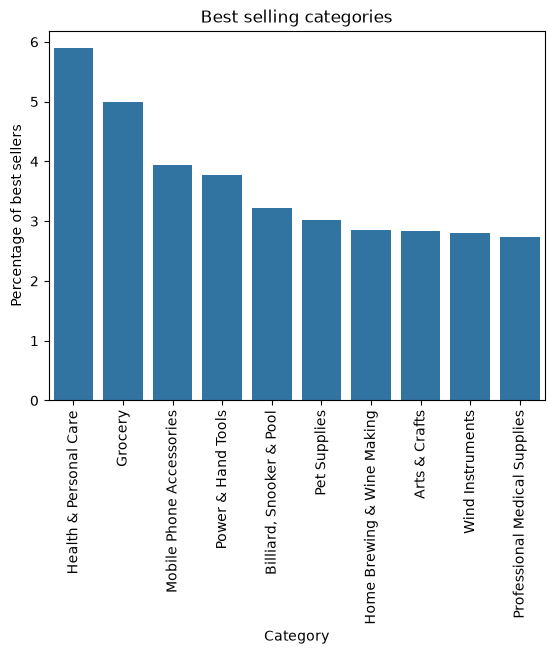

In [9]:
top10_cats_percent=best_percent_cats[:10]
sns.barplot(x=top10_cats_percent.index, y=top10_cats_percent["%True"])
plt.xlabel("Category")
plt.ylabel("Percentage of best sellers")
plt.title("Best selling categories")
plt.xticks(rotation=90)
plt.show()



chi square test

In [4]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(category_best)
print ("Chi2", chi2, "P ",p, "dof ", dof)
if p<5:
    print ("There is an association between category and isBestseller")
else: 
    print ("category and isBestseller are not associated")  
    
# Calculate Cramer's V
minimum_dimension = min(category_best.shape) -1
N = category_best.sum().sum()
cramersV = np.sqrt((chi2/N) / minimum_dimension)

print("cramers V: ",cramersV)





Chi2 43108.480615227585 P  0.0 dof  590
There is an association between category and isBestseller
cramers V:  0.09847050390094109


Chi square is large, and p is small (0.0), it means there is a strong association between both features
But Cramers V is small -> neligible association. The category alone doesn'say the product will be a bestseller.

In [43]:

category_20best = category_best[:20]
fig = go.Figure(data=[
    # Create the first set of bars for "TRUE" data
    go.Bar(name="True", x=category_20best.index, y=category_20best[True]),
    # Create the second set of bars for "fALSE" data
    go.Bar(name="False", x=category_20best.index, y=category_20best[False])  
    ])

# Change the type of the bars to "stacked" using update_layout
fig.update_layout(barmode="stack", title = "Category and x sales sorted by nr of bestsellers")


# Show the clustered and stacked bar chart
fig.show()

As very few % of the total products are best-sellers, it gets difficult to see this barplot. Especially one of the categories has a much higher number of products than the others. Removing the outlier (sports & Outdoors):


In [57]:
category_best.index
category_clean = category_best.drop(category_best.index[2])
category_20best = category_clean[:20]
fig = go.Figure(data=[
    # Create the first set of bars for "TRUE" data
    go.Bar(name="True", x=category_20best.index, y=category_20best[True]),
    # Create the second set of bars for "fALSE" data
    go.Bar(name="False", x=category_20best.index, y=category_20best[False])  
    ])

# Change the type of the bars to "stacked" using update_layout
fig.update_layout(barmode="stack", title = "Category and x sales sorted by nr of bestsellers")


# Show the clustered and stacked bar chart
fig.show()

#category_best.head

By remmoving the outlier, The proportion of best-sellers and non best-sellers can be seen.

Exploring Product Prices and Ratings Across Categories and Brands

Std dev: 360.62247482856134, min-max: 0.0-100000.0, iqr:37.71
count    1.918647e+06
mean     2.395084e+01
std      2.110952e+01
min      0.000000e+00
25%      9.460000e+00
50%      1.638000e+01
75%      3.048000e+01
max      1.042700e+02
Name: price, dtype: float64


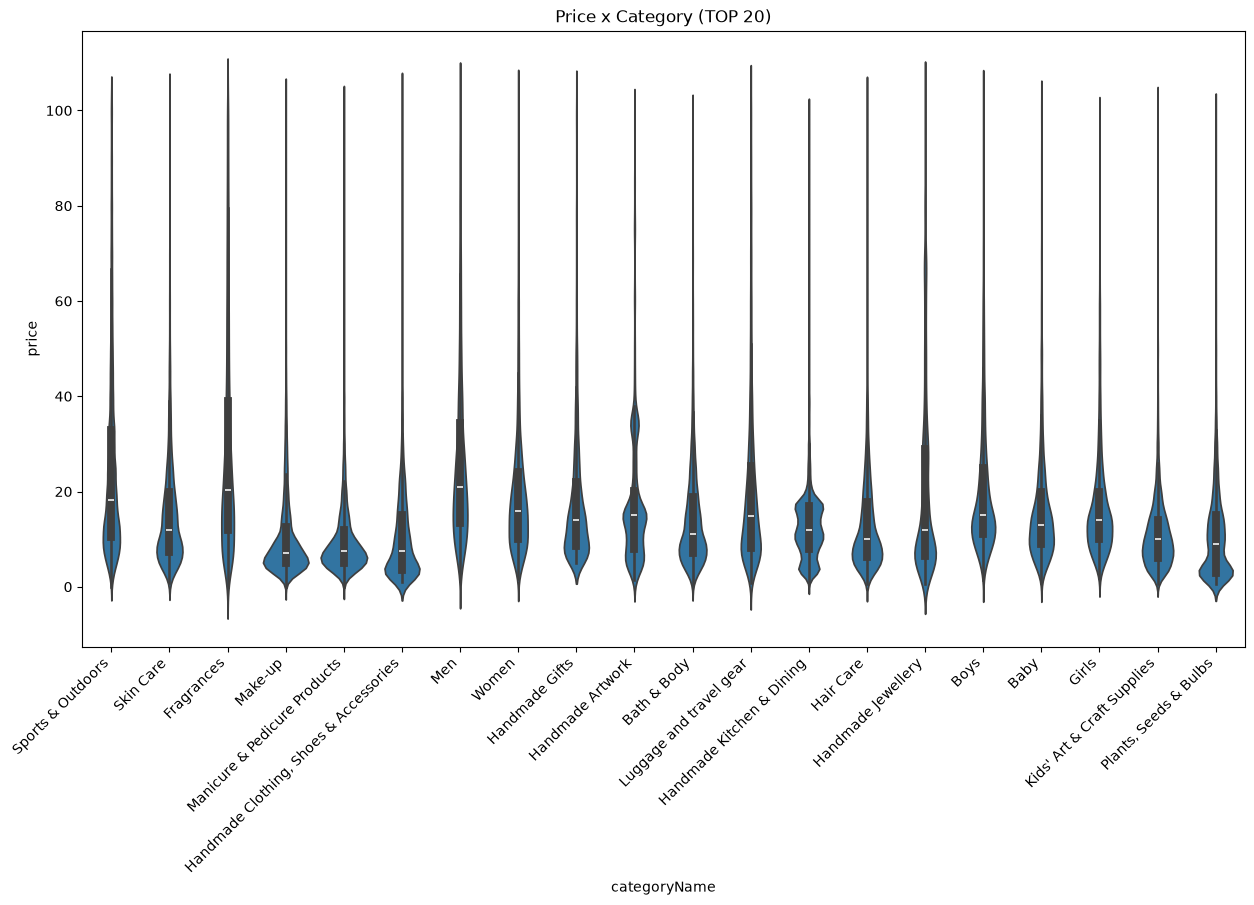

In [ ]:

# Remove outliers from product pricing:
price_std = df["price"].std()
price_min = df["price"].min()
price_max = df["price"].max()
price_q1 = df["price"].quantile(q=0.25)
price_q2 = df["price"].quantile(q=0.5)
price_q3 = df["price"].quantile(q=0.75)
price_iqr = price_q3 - price_q1
print( f"Std dev: {price_std}, min-max: {price_min}-{price_max}, iqr:{price_iqr}")
#print(df["price"].describe())

filter = (df["price"] >= price_q1-1.5*price_iqr ) & (df["price"] <= price_q3 + 1.5*price_iqr)
df_price_clean = df.loc[filter]
print(df_price_clean["price"].describe())


category_price = pd.crosstab(df_price_clean['price'], df_price_clean['categoryName'])
category_price = category_price.sort_values(
    by="price",
    ascending=False
)

#    Generate a frequency table for the product category.
# 1. sort the dataframe by category counts
df_price_clean["cat_counts"]= df_price_clean["categoryName"].map(df_price_clean["categoryName"].value_counts())
df_cat_sorted = df_price_clean.sort_values(by="cat_counts", ascending=False)



# 3.Get the top 20 categories for better visualisation:
top20 = df_price_clean["categoryName"].value_counts().head(20).index
df_price_top20 = df_price_clean[df_price_clean["categoryName"].isin(top20)]

# 4. sort
df_price_top20 = df_price_top20.sort_values(
    by="categoryName",
    key=lambda x: x.map(df["categoryName"].value_counts()),
    ascending=False
)

plt.figure(figsize=(15, 8))
sns.violinplot(data=df_price_top20,   x="categoryName", y="price" )
plt.title("Price x Category (TOP 20)")
#plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.show()



We can see that Fragrances, Men  and Sports&Outdoors have the highest median prices.
Categories with broader violin body have more concentration of values (e.g. Make-up, Manicure & Pedicure Products)


In [8]:
# Product category with highest median price
# 2. Group dataframe by categoryName
category_grouped = df_price_clean.groupby("categoryName")
median_prices = category_grouped["price"].median(numeric_only=True).sort_values(ascending=False)
print ( "The category with the highest median price is ", median_prices.index[0])



The category with the highest median price is  Desktop PCs


The category with the highest median price is  Desktop PCs

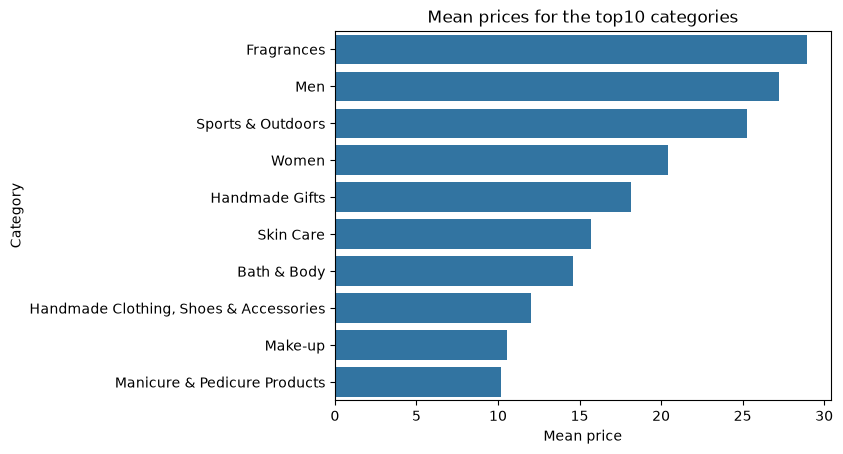

In [11]:
# average price of products:
mean_prices = category_grouped["price"].mean(numeric_only=True).sort_values(ascending=False)
top10_catcounts = df_price_clean["categoryName"].value_counts().head(10)

mean_prices_top10 = mean_prices.loc[median_prices.index.isin(top10_catcounts.index)]

# Create a bar chart 
sns.barplot(y=mean_prices_top10.index, x=mean_prices_top10.values)
plt.ylabel("Category")
plt.xlabel("Mean price")
plt.title("Mean prices for the top10 categories")
plt.show()


The category with highest median price is "Desktop PCs", and the category with highest mean prices is "Fragrances"

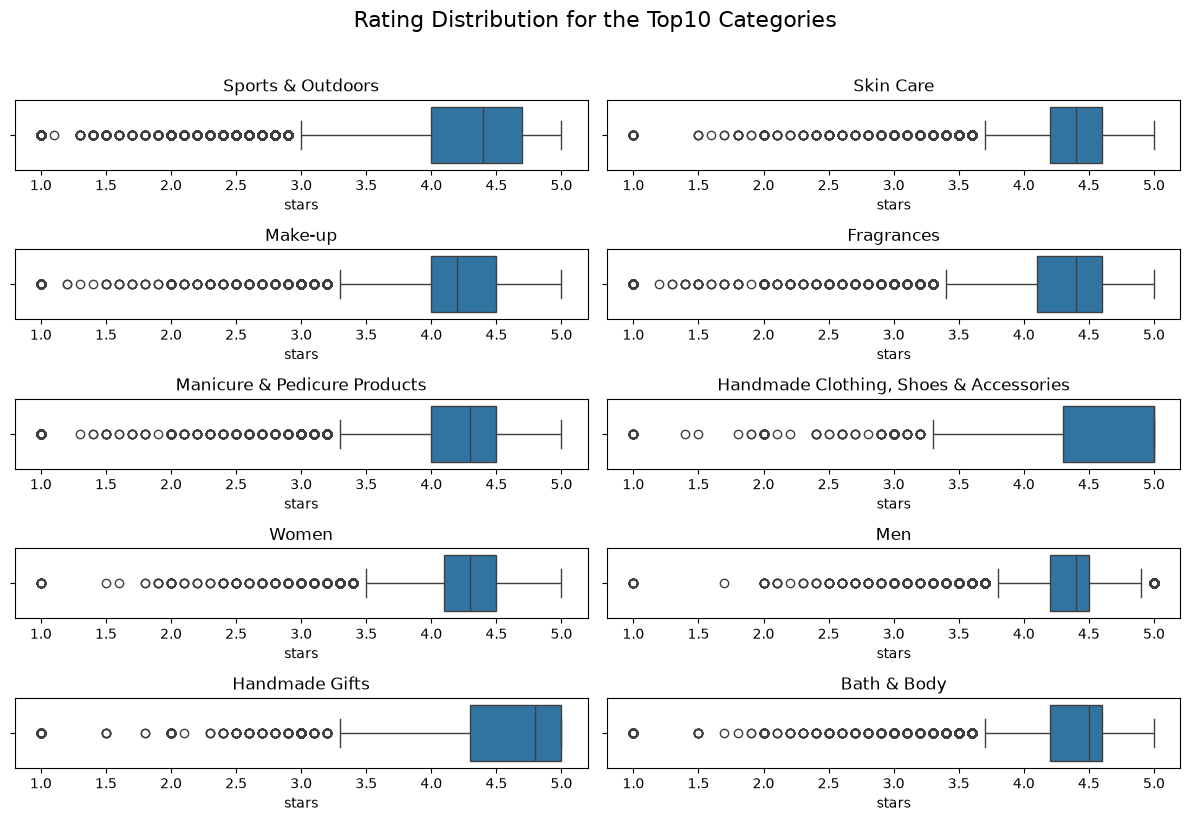

Index(['Birthday Gifts', 'Handmade Baby Products', 'Gifts for Him',
       'Handmade Clothing, Shoes & Accessories', 'Handmade Artwork',
       'Snowboards', 'Handmade Home Décor', 'Made in Italy Handmade',
       'Handmade Kitchen & Dining'],
      dtype='str', name='categoryName')
3.7
categoryName
Motorbike Instruments    3.7
Name: stars, dtype: float64


In [193]:
# First, clean the stars. Remove the zeros (no rating) from the dataset
df["stars"] = df["stars"].replace(0, np.nan)

category_grouped = df.groupby("categoryName")
ratings = category_grouped["stars"]

fig, axes = plt.subplots(5, 2, figsize=(12, 8))
fig.suptitle("Rating Distribution for the Top10 Categories", fontsize=16, y=1.02)

for ax, cat in zip(axes.flatten(), top10_catcounts.index):
    ax.set_title(str(cat))
    sns.boxplot(x=category_grouped.get_group(cat)["stars"],ax=ax)
plt.tight_layout()
plt.show()

# get the median of ratings by category

median_ratings=ratings.median().sort_values(ascending=False)
print(median_ratings[median_ratings==5].index)
print (median_ratings.values.min())
print (median_ratings[median_ratings == median_ratings.values.min()])

The percentage of ratings (measured as number of stars, the hitgher the better) are, as seen before, very low. If people rate, they tend to give high ratings. Some categories had the maximum rating as median: 'Birthday Gifts', 'Handmade Baby Products', 'Gifts for Him',
       'Handmade Clothing, Shoes & Accessories', 'Handmade Artwork',
       'Snowboards', 'Handmade Home Décor', 'Made in Italy Handmade',
       'Handmade Kitchen & Dining'.
The lowest median rating was 3.7, for the category 'Motorbike Instruments'

In [12]:
#Correlation Coefficients:
from scipy import stats

#    Calculate the correlation coefficient between price and stars.
#    Is there a significant correlation between product price and its rating?
corr_data = df[["price", "stars"]].dropna()   # eliminate Nans ( the zero ratings)

# Significance: scipy returns the coefficient AND a p-value (H0: no correlation)
r, p = stats.pearsonr(corr_data["price"], corr_data["stars"])
rho, p_s = stats.spearmanr(corr_data["price"], corr_data["stars"])
print(f"Pearson r = {r:.2f} (p = {p:.1e})  |  Spearman ρ = {rho:.2f} (p = {p_s:.1e})")
# trying with the cleaned price dataset
corr_data2 = df_price_clean[["price", "stars"]].dropna()
r, p = stats.pearsonr(corr_data["price"], corr_data["stars"])
rho, p_s = stats.spearmanr(corr_data2["price"], corr_data2["stars"])
print(f"Pearson r = {r:.2f} (p = {p:.1e})  |  Spearman ρ = {rho:.2f} (p = {p_s:.1e})")

Pearson r = -0.12 (p = 0.0e+00)  |  Spearman ρ = -0.12 (p = 0.0e+00)
Pearson r = -0.12 (p = 0.0e+00)  |  Spearman ρ = -0.05 (p = 0.0e+00)


Pearsons r is 0, spearmans rho is very smalll -> no or weak linear correlation

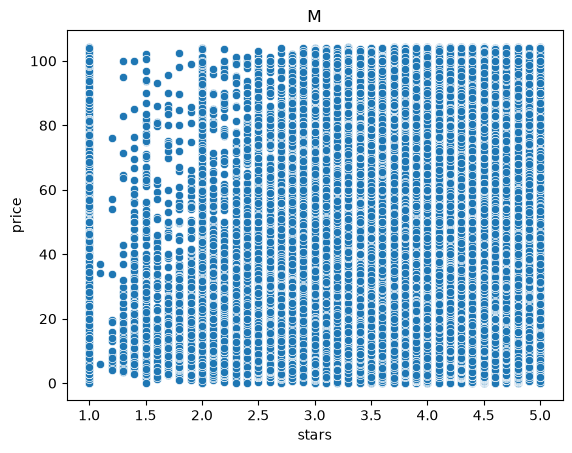

In [15]:
# Only for the non zero stars (the real ratings), removing price outliers
df_nonzero= df_price_clean[df_price_clean["stars"] != 0].copy()
sns.scatterplot(data=df_nonzero,  x="stars", y="price")
plt.title("M")
plt.show()

The scatterplot above does not show a correlation.

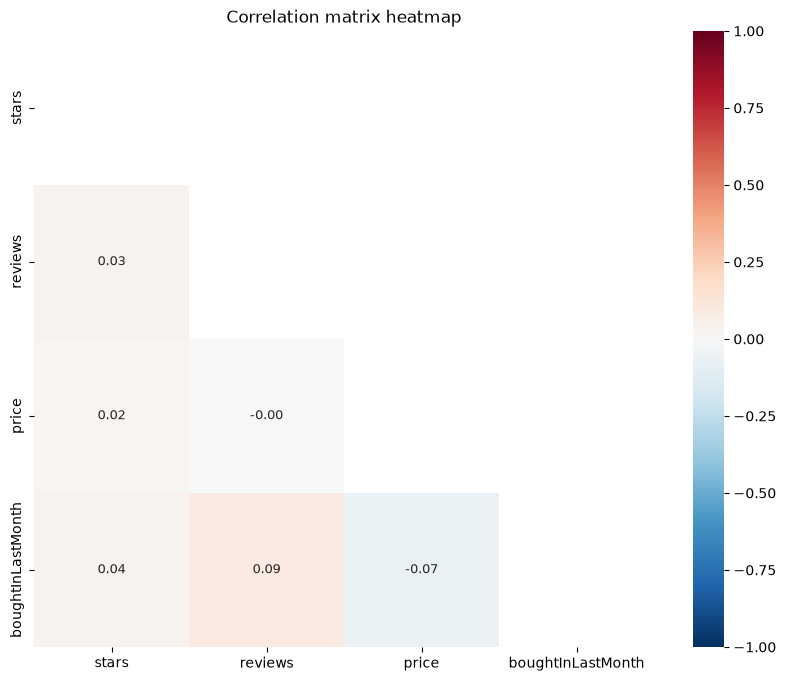

,stars,reviews,price,boughtInLastMonth
stars,1.000000,0.032754,0.015821,0.036266
reviews,0.032754,1.000000,-0.000658,0.089501
price,0.015821,-0.000658,1.000000,-0.067496
boughtInLastMonth,0.036266,0.089501,-0.067496,1.000000


In [16]:
df_nonzero = df_nonzero.drop(columns=["cat_counts"])
numerical = df_nonzero.select_dtypes(include="number")
  # cat counts is not in the original db
corr_matrix = numerical.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 9}, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation matrix heatmap")
plt.show()
corr_matrix

It shows again very weak to no correlation.

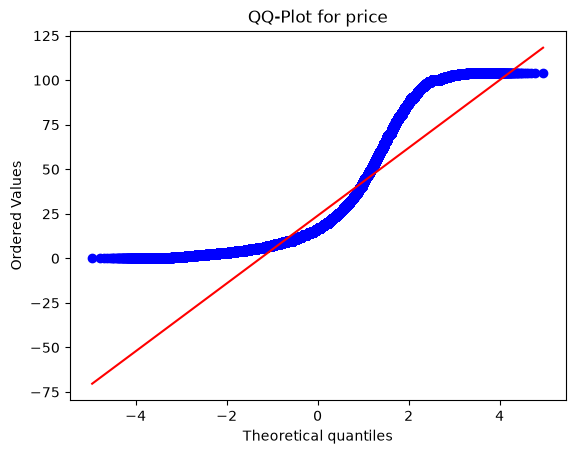

In [237]:
stats.probplot(df_price_clean["price"], dist="norm", plot=plt)
plt.title("QQ-Plot for price")
plt.show()

The distribution of price (the cleaned data, without outliers) shows an s-shaled curve, it means that it is heavy tailed, differing from a normal distribution.